In [1]:
import numpy as np

In [2]:
xmin=0
xmax=4*np.pi
vmin=-6
vmax=6
tmax=120

Nx = 1024
Nv= 128
Nt=200

x_arr,dx = np.linspace(xmin, xmax, Nx, endpoint=False, retstep=True)
v_arr, dv = np.linspace(vmin, vmax, Nv, endpoint=False, retstep=True)

Teq=1
eps_bot=0.1
T_bot=0.1
epsilon=0.001
kx=0.5

# Initialize distribution function
X, V = np.meshgrid(x_arr, v_arr)

VPtype="landau_damping"

if VPtype == "landau_damping":
    feq = 1.0/np.sqrt(2.0*np.pi*Teq)* np.exp(-0.5*V*V/Teq)
elif VPtype == "bump-on-tail":
    f1_eq = (1.0-eps_bot)/np.sqrt(2.*np.pi*Teq)*np.exp(-0.5*V*V/Teq)  
    f2_eq = eps_bot/np.sqrt(2.*T_bot) * np.exp(-(V-V_bot)*(V-V_bot)/(2.*T_bot))
    feq = f1_eq + f2_eq

fdistribu = feq * (1.0 + epsilon*np.cos(kx*X))
fdistribu = fdistribu.T
feq = feq.T

# Set time domain
timegrid, dt = np.linspace(0.0, tmax, Nt, retstep=True)

# Set the output distribution function and electric field
fdistribu_evol = np.zeros((Nt, Nx, Nv))
fdistribu_evol[0, :] = fdistribu
efield_evol = np.zeros((Nt, Nx))

In [11]:
a=np.shape(fdistribu)[1]
a

128

In [3]:
def advection_x(f, dt):

    alpha = dt * v_arr
    # self.f[:, j] = self.cs_x.interpolate_disp(self.f[:, j], alpha)
    f_new = np.stack([
        np.interp(x_arr-alpha[j], x_arr, f[:, j],period=xmax-xmin)
        for j in range(Nv)
    ], axis=1)
    return f_new

def advection_v(f, efield, dt):
    alpha = dt * efield
    # self.f[i, :] = self.cs_v.interpolate_disp(self.f[i, :], alpha)
    f_new = np.stack([
        np.interp(v_arr-alpha[i], v_arr, f[i, :])
        for i in range(Nx)
    ], axis=0)
    return f_new
    

In [4]:
from scipy.fft import fft, ifft
from scipy.fft import fftfreq  # noqa: F401

def compute_rho(f):
    return dv * np.sum(f, axis=1)


def compute_efield(rho):
    modes=np.zeros(Nx)
    k = 2 * np.pi / (xmax - xmin)
    modes= k*Nx*fftfreq(Nx)
    modes+=modes==0

    rhok=fft(rho)/modes ##Rho/k
    return np.real(ifft(-1j*rhok)) #Inverse transform of \hat E

In [5]:
energia=[]

fdistribu=advection_x(fdistribu_evol[0,:,:],0.5*dt)

for i in range(Nt):
    rho=compute_rho(fdistribu)
    e_f=compute_efield(rho)
    fdistribu=advection_v(fdistribu,e_f,dt)
    fdistribu=advection_x(fdistribu,dt)
    energia.append(0.5*np.log(np.sum(e_f * e_f) * dx))

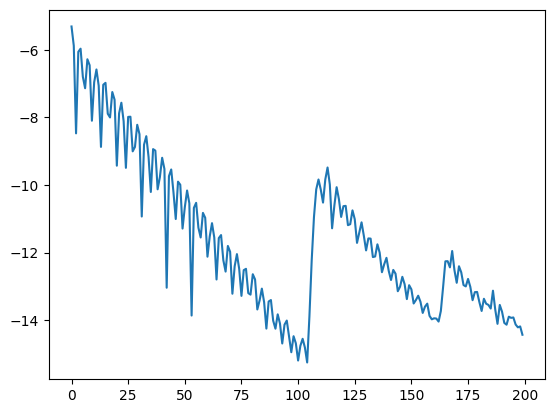

In [6]:
import matplotlib.pyplot as plt
plt.plot(energia)

In [7]:
#   
#  The 1D1V Vlasov-Poisson solved with Semi-Lagrangian method
#
# Written by P. Navaro (https://github.com/pnavaro)
#   see https://pnavaro.github.io/python-notebooks/19-LandauDamping.html
#---------------------------------------------------------------------

import numpy as np
from tqdm import tqdm

import bsl as bs


class VlasovPoisson:
    """
    Solve the 2D Vlasov-Poisson problem in (x,v).
    ATTENTION: x must be periodic
    """

    def __init__(self, xmin, xmax, nx, vmin, vmax, nv):
        # Grid
        self.nx = nx
        self.x, self.dx = np.linspace(xmin, xmax, nx, endpoint=False, retstep=True)
        self.nv = nv
        self.v, self.dv = np.linspace(vmin, vmax, nv, endpoint=False, retstep=True)

        # Distribution function
        self.f = np.zeros((nx, nv))

        # Interpolators for advection
        self.cs_x = bs.BSpline(3, xmin, xmax, nx)
        self.cs_v = bs.BSpline(3, vmin, vmax, nv)

        # Modes for Poisson equation
        self.modes = np.zeros(nx)
        k = 2 * np.pi / (xmax - xmin)
        self.modes = k * nx * bs.fftfreq(nx)
        self.modes += self.modes == 0  # avoid division by zero

    def advection_x(self, dt):
        for j in range(self.nv):
            alpha = dt * self.v[j]
            self.f[:, j] = self.cs_x.interpolate_disp(self.f[:, j], alpha)

    def advection_v(self, efield, dt):
        for i in range(self.nx):
            alpha = dt * efield[i]
            self.f[i, :] = self.cs_v.interpolate_disp(self.f[i, :], alpha)

    def compute_rho(self):
        return self.dv * np.sum(self.f, axis=1)

    def compute_efield(self, rho):
        # compute Ex using that ik*Ex = rho
        rhok = bs.fft(rho) / self.modes
        return np.real(bs.ifft(-1j * rhok))

    def run(self, f, nstep, dt, F, efield):
        self.f = f
        nrj = []
        self.advection_x(0.5 * dt)
        for istep in tqdm(range(nstep)):
            rho = self.compute_rho()
            efield[istep] = self.compute_efield(rho)
            self.advection_v(efield[istep], dt)
            self.advection_x(dt)
            nrj.append(0.5 * np.log(np.sum(efield[istep] * efield[istep]) * self.dx))
            F[istep, :] = self.f
        return nrj, F, efield

    def test_run(self, f, nstep, dt):
        self.f = f
        nrj = []
        self.advection_x(0.5 * dt)
        for istep in tqdm(range(nstep)):
            rho = self.compute_rho()
            efield = self.compute_efield(rho)
            self.advection_v(efield, dt)
            self.advection_x(dt)
            nrj.append(0.5 * np.log(np.sum(efield * efield) * self.dx))

        return nrj
